## count how many fingers

In [11]:
import cv2
import math
import urllib.request
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

In [12]:
url = ("https://storage.googleapis.com/mediapipe-models/"
       "hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task")
urllib.request.urlretrieve(url, "hand_landmarker.task")
print("Model downloaded")

Model downloaded


In [13]:
options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.7,
)
detector = vision.HandLandmarker.create_from_options(options)

In [14]:
# (tip, joint below the tip) landmark indices for the four fingers
FINGERS = {"Index": (8, 6), "Middle": (12, 10), "Ring": (16, 14), "Pinky": (20, 18)}

def get_raised_fingers(hand, w, h):
    """hand = 21 landmarks. Returns a list of the raised fingers' names."""
    pts = [(lm.x * w, lm.y * h) for lm in hand]      # pixel coordinates

    def dist(a, b):
        return math.hypot(pts[a][0] - pts[b][0], pts[a][1] - pts[b][1])

    raised = []

    # Thumb: tip is farther from the pinky base (17) than the thumb's middle joint (3)
    if dist(4, 17) > dist(3, 17):
        raised.append("Thumb")

    # Other fingers: tip is farther from the wrist (0) than the middle joint
    for name, (tip, joint) in FINGERS.items():
        if dist(tip, 0) > dist(joint, 0):
            raised.append(name)

    return raised

In [15]:
TIP_IDS = {"Thumb": 4, "Index": 8, "Middle": 12, "Ring": 16, "Pinky": 20}

def count_fingers(frame):
    h, w, _ = frame.shape
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = detector.detect(mp_image)

    total = 0
    for hand in result.hand_landmarks:
        raised = get_raised_fingers(hand, w, h)
        total += len(raised)

        # draw all landmarks in yellow, raised fingertips in green
        for lm in hand:
            cv2.circle(frame, (int(lm.x * w), int(lm.y * h)), 4, (0, 255, 255), -1)
        for name in raised:
            tip = hand[TIP_IDS[name]]
            cv2.circle(frame, (int(tip.x * w), int(tip.y * h)), 10, (0, 255, 0), -1)

        # number of fingers for this hand, near the wrist
        wrist = hand[0]
        cv2.putText(frame, str(len(raised)), (int(wrist.x * w) - 10, int(wrist.y * h) + 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)

    cv2.putText(frame, f"Total fingers: {total}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    return frame

In [17]:
cap = cv2.VideoCapture(0)

while True:
    ok, frame = cap.read()
    if not ok:
        break

    frame = cv2.flip(frame, 1)       # mirror view
    frame = count_fingers(frame)

    cv2.imshow("finger", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

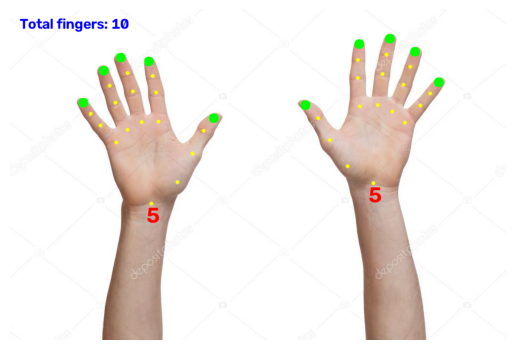

In [19]:
import matplotlib.pyplot as plt

frame = cv2.imread("hands.jpg")       # put your image path here
frame = count_fingers(frame)

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()